In [ ]:
import gc
import optuna
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM , Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
import os
import random


In [ ]:
os.environ["PYTHONHASHSEED"] = "42"
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()


In [ ]:

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if gpus:
    print("GPU is enabled!")
else:
    print("GPU not detected")

GPU is enabled!


In [51]:
df = pd.read_csv('MSFT Historical Data.csv')
df["Date"] =pd.to_datetime(df["Date"], errors='coerce')
df = df.sort_values('Date').drop_duplicates(subset='Date').reset_index(drop=True)
price_col = [ 'Price', 'Open', 'High', 'Low']
for col in price_col:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False).str.strip(),errors="coerce")
def parse_volume(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip().upper().replace(",", "")

    if s in {"", "-", "--", "NAN", "N/A"}:
        return np.nan

    multipliers = {
        "K": 1e3,
        "M": 1e6,
        "B": 1e9,
        "T": 1e12
    }

    if s[-1] in multipliers:
        return float(s[:-1]) * multipliers[s[-1]]

    return float(s)


df["Vol."] = df["Vol."].apply(parse_volume)

df =df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Date", "Price", "Open", "High", "Low", "Vol."]).reset_index(drop=True)

df["log_volume"] = np.log1p(df["Vol."])

feature_cols = ['Price', 'Open', 'High', 'Low', 'log_volume']
prev_cnt = 30
n = len(df)
train_end = int(n*0.75)
val_end = int(n*0.85)

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_scaler.fit(df.iloc[:train_end][ feature_cols])
y_scaler.fit(df.iloc[prev_cnt:train_end][ ["Price"]])

x_scaled = x_scaler.transform(df[feature_cols]).astype(np.float32)

y_scaled = y_scaler.transform(df[["Price"]]).astype(np.float32)

X,y ,tar_indices = [],[],[]
for i in range(prev_cnt, len(df)):
    X.append(x_scaled[i-prev_cnt:i])
    y.append(y_scaled[i])
    tar_indices.append(i)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
tar_indices = np.asarray(tar_indices)
train_mask = tar_indices < train_end
val_mask = (tar_indices >= train_end) & (tar_indices < val_end)
test_mask = tar_indices >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

/tmp/ipykernel_507/34327650.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] =pd.to_datetime(df["Date"], errors='coerce')


In [52]:
def objective(trial):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    n_layers = trial.suggest_int("n_layers",1,3)
    dropout = trial.suggest_float("dropout",0.0,0.35)
    learning_rate = trial.suggest_float("learning_rate",1e-4,3e-3,log = True)
    batch_size = trial.suggest_categorical("batch_size",[32,64])
    units = [trial.suggest_categorical(f"units_{i}", [64,96,128]) for i in range(n_layers)]
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))
    for i, u in enumerate(units):
        model.add(LSTM(u,return_sequences=(i< n_layers-1)))
        if i<n_layers-1:
            model.add(Dropout(dropout))
    model.add(Dense(trial.suggest_categorical("dense_units",[16,32,64]),activation='relu'))
    model.add(Dense(1))
    model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=learning_rate), loss="mse" , metrics=["mae"])
    class Optunacallback(tf.keras.callbacks.Callback):
        def on_epoch_end(self, epoch,logs=None):
            value = (logs or {}).get("val_mae")
            if value is not None:
                trial.report(float(value), step=epoch)
                if trial.should_prune():
                    self.model.stop_training = True
                    raise optuna.TrialPruned()



    early_stopping = EarlyStopping(monitor= 'val_mae',patience=15,min_delta=1e-5,mode="min",restore_best_weights=True)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mae",factor=0.5,patience=5,min_lr=1e-6,verbose=1)
    hst = model.fit(X_train, y_train, epochs=90, batch_size=batch_size, validation_data=(X_val, y_val), callbacks=[early_stopping, reduce_lr, Optunacallback()])
    best_mae = min(hst.history["val_mae"])
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return float(best_mae)
sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(study_name = "lstm_tuningv2",direction="minimize",
            pruner = optuna.pruners.MedianPruner(n_startup_trials=5,n_warmup_steps=10),
            storage="sqlite:///lstm_tuningv2.db",
            load_if_exists=True, sampler = sampler
        )

study.optimize(objective, n_trials=30)


[I 2026-10-13 17:39:17,683] A new study created in RDB with name: lstm_tuningv2


Epoch 1/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0069 - mae: 0.0378 - val_loss: 1.3887e-04 - val_mae: 0.0089 - learning_rate: 0.0012
Epoch 2/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.0872e-04 - mae: 0.0169 - val_loss: 1.2025e-04 - val_mae: 0.0084 - learning_rate: 0.0012
Epoch 3/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 6.1171e-04 - mae: 0.0158 - val_loss: 1.8550e-04 - val_mae: 0.0111 - learning_rate: 0.0012
Epoch 4/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 6.3441e-04 - mae: 0.0162 - val_loss: 1.8282e-04 - val_mae: 0.0111 - learning_rate: 0.0012
Epoch 5/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 5.1102e-04 - mae: 0.0145 - val_loss: 1.8084e-04 - val_mae: 0.0111 - learning_rate: 0.0012
Epoch 6/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 5.3562e-04 - mae: 0.0149 - val_loss: 1.3518e-04 - val_mae: 0.0093 - learning_rate: 0.0012
Epoch 7/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 4.7630e-04 - mae: 0.0139 - val_loss: 9.

[I 2026-10-13 17:41:28,515] Trial 0 finished with value: 0.004247823730111122 and parameters: {'n_layers': 2, 'dropout': 0.33275000724347065, 'learning_rate': 0.001205712628744377, 'batch_size': 32, 'units_0': 128, 'units_1': 96, 'dense_units': 16}. Best is trial 0 with value: 0.004247823730111122.


Epoch 1/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0216 - mae: 0.0693 - val_loss: 1.2313e-04 - val_mae: 0.0082 - learning_rate: 2.8145e-04
Epoch 2/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 4.6767e-04 - mae: 0.0134 - val_loss: 1.1604e-04 - val_mae: 0.0080 - learning_rate: 2.8145e-04
Epoch 3/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 4.3970e-04 - mae: 0.0127 - val_loss: 1.1034e-04 - val_mae: 0.0078 - learning_rate: 2.8145e-04
Epoch 4/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.1842e-04 - mae: 0.0124 - val_loss: 1.1892e-04 - val_mae: 0.0082 - learning_rate: 2.8145e-04
Epoch 5/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.9547e-04 - mae: 0.0120 - val_loss: 1.2375e-04 - val_mae: 0.0086 - learning_rate: 2.8145e-04
Epoch 6/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.7360e-04 - mae: 0.0117 - val_loss: 1.1984e-04 - val_mae: 0.0085 - learning_rate: 2.8145e-04
Epoch 7/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.5409e-04 - mae: 

[I 2026-10-13 17:42:10,874] Trial 1 finished with value: 0.00543596874922514 and parameters: {'n_layers': 1, 'dropout': 0.06419157844870184, 'learning_rate': 0.0002814509271606064, 'batch_size': 32, 'units_0': 96, 'dense_units': 64}. Best is trial 0 with value: 0.004247823730111122.


...

[I 2026-10-13 18:03:11,987] Trial 27 finished with value: 0.003982702735811472 and parameters: {'n_layers': 1, 'dropout': 0.3473145167241066, 'learning_rate': 0.0014084021675630951, 'batch_size': 32, 'units_0': 96, 'dense_units': 32}. Best is trial 21 with value: 0.003466801019385457.


Epoch 1/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0033 - mae: 0.0264 - val_loss: 9.1940e-05 - val_mae: 0.0071 - learning_rate: 0.0013
Epoch 2/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3.1977e-04 - mae: 0.0107 - val_loss: 7.9409e-05 - val_mae: 0.0065 - learning_rate: 0.0013
Epoch 3/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.9471e-04 - mae: 0.0102 - val_loss: 9.1039e-05 - val_mae: 0.0073 - learning_rate: 0.0013
Epoch 4/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.8131e-04 - mae: 0.0101 - val_loss: 1.0343e-04 - val_mae: 0.0080 - learning_rate: 0.0013
Epoch 5/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.7501e-04 - mae: 0.0101 - val_loss: 1.0329e-04 - val_mae: 0.0081 - learning_rate: 0.0013
Epoch 6/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.6689e-04 - mae: 0.0100 - val_loss: 1.0493e-04 - val_mae: 0.0082 - learning_rate: 0.0013
Epoch 7/90
113/117 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.0498e-04 - mae: 0.0107
Epoch 7: ReduceLRO

[I 2026-10-13 18:04:18,741] Trial 28 finished with value: 0.003840088378638029 and parameters: {'n_layers': 1, 'dropout': 0.2866328477865463, 'learning_rate': 0.0012930378706580306, 'batch_size': 32, 'units_0': 96, 'dense_units': 32}. Best is trial 21 with value: 0.003466801019385457.


Epoch 1/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0068 - mae: 0.0402 - val_loss: 1.4698e-04 - val_mae: 0.0094 - learning_rate: 0.0026
Epoch 2/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 7.0951e-04 - mae: 0.0175 - val_loss: 1.2400e-04 - val_mae: 0.0087 - learning_rate: 0.0026
Epoch 3/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 6.1306e-04 - mae: 0.0159 - val_loss: 9.6626e-05 - val_mae: 0.0075 - learning_rate: 0.0026
Epoch 4/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 6.1579e-04 - mae: 0.0158 - val_loss: 1.1717e-04 - val_mae: 0.0083 - learning_rate: 0.0026
Epoch 5/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 4.8898e-04 - mae: 0.0138 - val_loss: 2.1785e-04 - val_mae: 0.0126 - learning_rate: 0.0026
Epoch 6/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.2630e-04 - mae: 0.0151 - val_loss: 2.6544e-04 - val_mae: 0.0143 - learning_rate: 0.0026
Epoch 7/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 4.7972e-04 - mae: 0.0141 - val_loss: 

[I 2026-10-13 18:04:38,525] Trial 29 pruned. 


In [53]:
study.best_params

{'n_layers': 1,
 'dropout': 0.32630345769372293,
 'learning_rate': 0.0029583789780168205,
 'batch_size': 32,
 'units_0': 96,
 'dense_units': 32}

In [54]:
study.best_value

0.003466801019385457

In [55]:
def build_model(params, input_shape):
  model = Sequential()
  model.add(Input(shape = input_shape))
  n = params["n_layers"]
  dropout =params["dropout"]

  for i in range(n):
    units = params[f"units_{i}"]
    model.add(LSTM(units,return_sequences=(i<n-1)))
    if i<n-1:
      model.add(Dropout(dropout))
  model.add(Dense(params["dense_units"],activation='relu'))
  model.add(Dense(1))
  optimizer = tf.keras.optimizers.Adam(learning_rate=params["learning_rate"],clipnorm=1.0)
  model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])
  return model

In [56]:
final_model = build_model(params = study.best_params, input_shape = (X_train.shape[1], X_train.shape[2]))
batch_size = study.best_params["batch_size"]
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath="/content/best_lstm_model.keras", monitor="val_mae",mode="min" , save_best_only=True)
early_stopping = EarlyStopping(monitor= 'val_mae',patience=15,min_delta=1e-5,mode="min",restore_best_weights=True)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_mae",factor=0.5,patience=5,min_lr=1e-6,verbose=1)
hst = final_model.fit(X_train, y_train, epochs=90, batch_size=batch_size, validation_data=(X_val, y_val), callbacks=[early_stopping, reduce_lr,checkpoint])





Epoch 1/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0039 - mae: 0.0255 - val_loss: 1.2186e-04 - val_mae: 0.0078 - learning_rate: 0.0030
Epoch 2/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 3.0612e-04 - mae: 0.0113 - val_loss: 1.2339e-04 - val_mae: 0.0083 - learning_rate: 0.0030
Epoch 3/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.7690e-04 - mae: 0.0106 - val_loss: 9.4935e-05 - val_mae: 0.0071 - learning_rate: 0.0030
Epoch 4/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.5161e-04 - mae: 0.0101 - val_loss: 8.3244e-05 - val_mae: 0.0067 - learning_rate: 0.0030
Epoch 5/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.3863e-04 - mae: 0.0098 - val_loss: 9.7814e-05 - val_mae: 0.0079 - learning_rate: 0.0030
Epoch 6/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.0425e-04 - mae: 0.0089 - val_loss: 1.6218e-04 - val_mae: 0.0111 - learning_rate: 0.0030
Epoch 7/90
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.1331e-04 - mae: 0.0092 - val_loss: 1.4906

In [57]:
best_epoch = int(np.argmin(hst.history["val_mae"])+1)
best_val_mae = float(min(hst.history["val_mae"]))
print(best_epoch,best_val_mae)

33 0.0034831941593438387


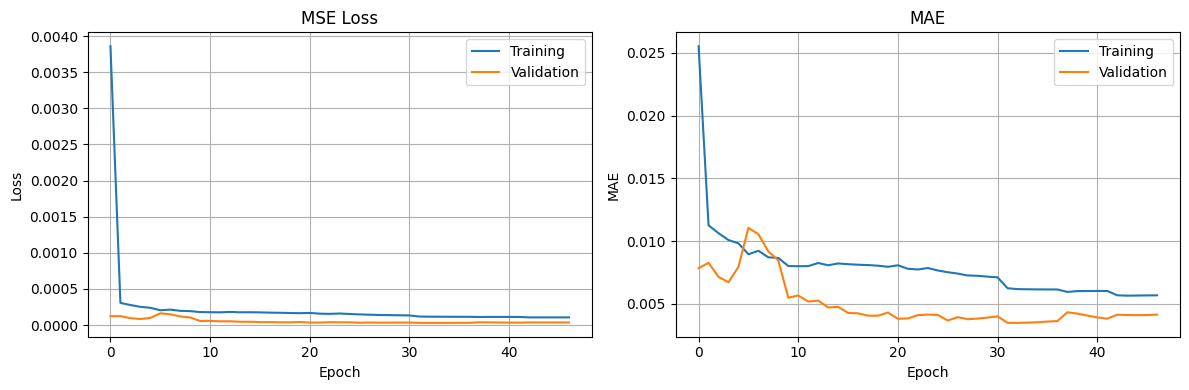

In [58]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hst.history["loss"], label="Training")
axes[0].plot(hst.history["val_loss"], label="Validation")
axes[0].set_title("MSE Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(hst.history["mae"], label="Training")
axes[1].plot(hst.history["val_mae"], label="Validation")
axes[1].set_title("MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MAE")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [59]:
pred_scaled = final_model.predict(X_test)
pred_close = y_scaler.inverse_transform(pred_scaled).ravel()
actual_close = y_scaler.inverse_transform(y_test).ravel()
mae = mean_absolute_error(actual_close, pred_close)
rmse = np.sqrt(mean_squared_error(actual_close, pred_close))

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [60]:
print(f"Test MAE:{mae}")
print(f"Test RMSE:{rmse}")

Test MAE:0.4170941710472107
Test RMSE:0.590686448750677
